In [1]:
# EG L = 3，6 的结果不是想要的

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.sparse import csr_matrix
import scvelo as scv
from torch.optim import SGD, Adam, Adagrad
from function import *

from utils import *
from g2g_model_Fisher import *
import itertools

In [3]:
data_path = "/home/linux/桌面/SCIM-main/main/data/branch_data/"
path_path = "/home/linux/桌面/Is single cell sloppy?/4_FI_vs_Velocity/RC_path/"
cmap = plt.colormaps['Spectral_r']
save = False

[k_nei, K, L] = [10, 3, 3]
computing neighbors
    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'lo

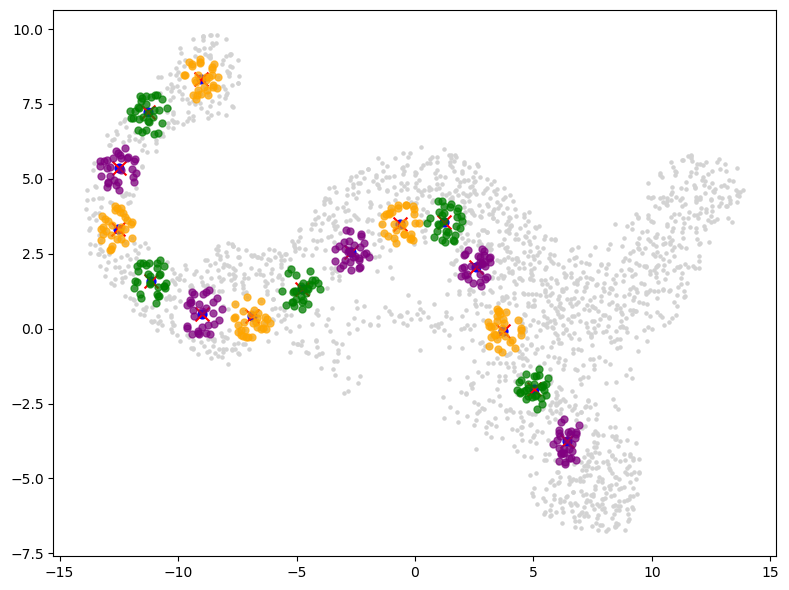

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

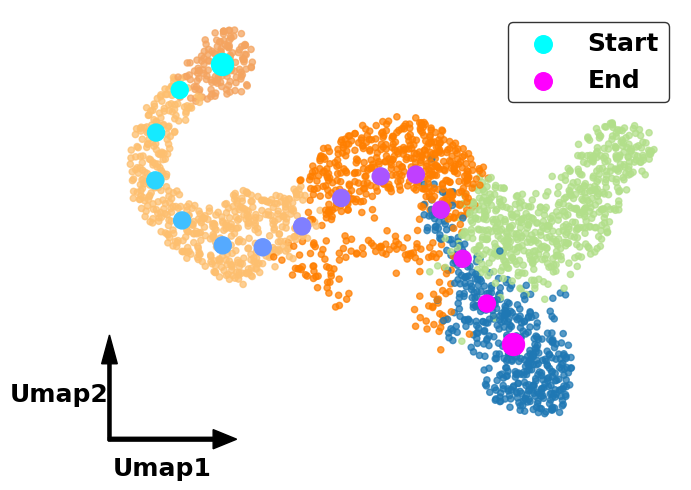

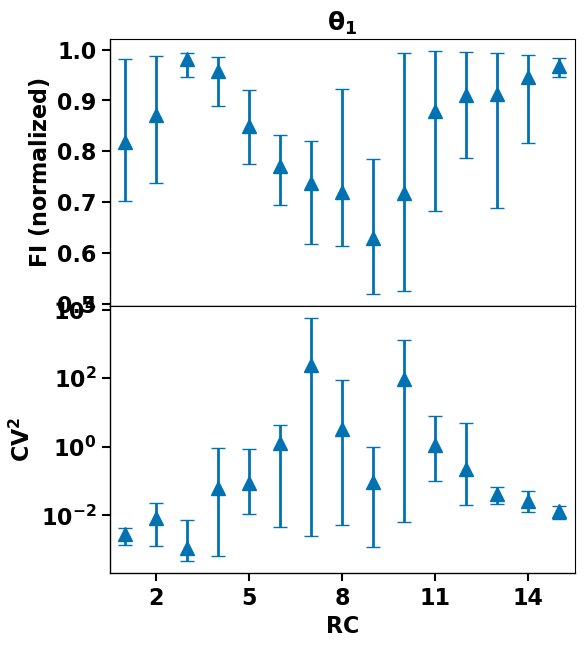

new_array.shape (15, 30, 3)
y: [2.8011291e-03 8.4883673e-03 1.0889926e-03 6.2086295e-02 8.7230317e-02
 1.2684095e+00 2.4832588e+02 3.3042796e+00 9.1724269e-02 9.3129768e+01
 1.1480806e+00 2.2826184e-01 4.1607466e-02 2.6892105e-02 1.3666093e-02]
max_vals: [4.2317621e-03 2.3164792e-02 7.5177974e-03 9.4812471e-01 8.4356928e-01
 4.4492197e+00 5.5495654e+03 8.6214645e+01 9.8679602e-01 1.3081224e+03
 7.9350705e+00 5.0056195e+00 6.7687310e-02 5.2722853e-02 1.8390588e-02]
min_vals: [0.00136736 0.00125822 0.00046419 0.00064621 0.01091389 0.00450031
 0.00242903 0.00514357 0.00122152 0.00633776 0.09781486 0.02028635
 0.02174893 0.01285132 0.00763127]
error: [[1.4337704e-03 7.2301440e-03 6.2480464e-04 6.1440084e-02 7.6316424e-02
  1.2639092e+00 2.4832346e+02 3.2991359e+00 9.0502754e-02 9.3123428e+01
  1.0502658e+00 2.0797549e-01 1.9858532e-02 1.4040783e-02 6.0348199e-03]
 [1.4306330e-03 1.4676425e-02 6.4288047e-03 8.8603842e-01 7.5633895e-01
  3.1808102e+00 5.3012397e+03 8.2910362e+01 8.9507174e-0

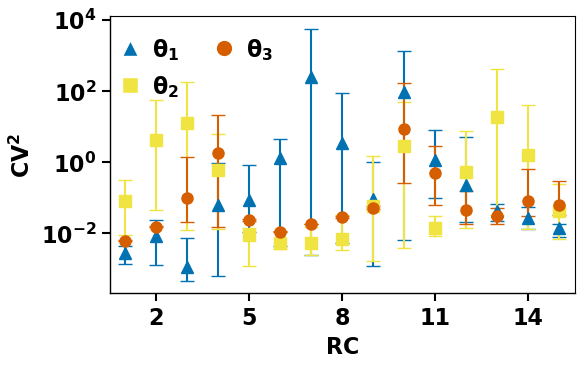

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighb

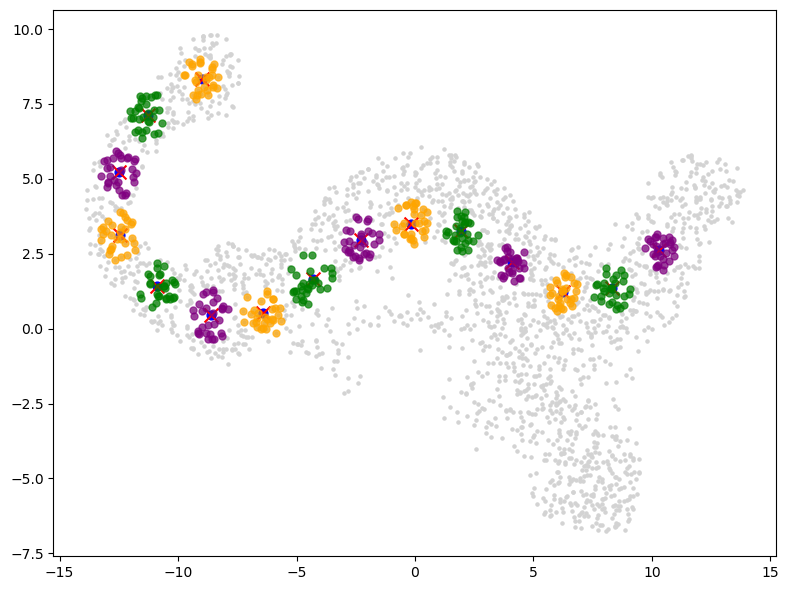

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

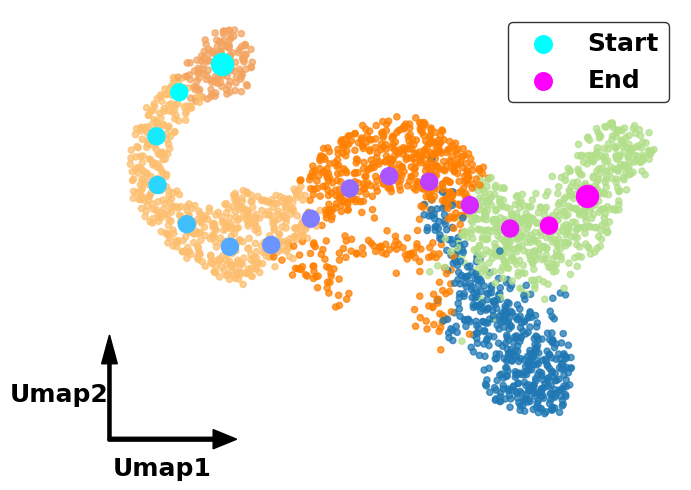

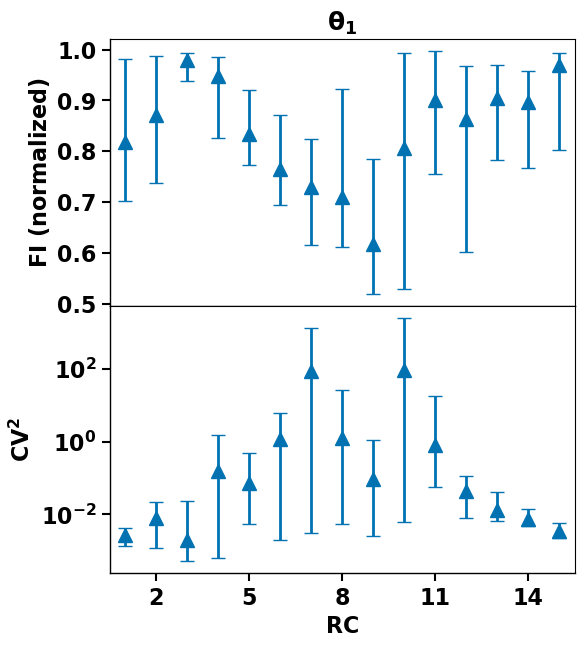

new_array.shape (15, 30, 3)
y: [2.8011291e-03 7.9915570e-03 1.9922478e-03 1.5128623e-01 7.3750257e-02
 1.2103951e+00 8.7076813e+01 1.2586561e+00 9.5813490e-02 9.0207558e+01
 8.1448460e-01 4.2861950e-02 1.3257527e-02 7.7249459e-03 3.5992207e-03]
max_vals: [4.2317621e-03 2.2140509e-02 2.3775747e-02 1.5429840e+00 4.7402355e-01
 5.9292107e+00 1.3070426e+03 2.5457380e+01 1.1050376e+00 2.4231277e+03
 1.7999218e+01 1.1027679e-01 4.2384285e-02 1.3882146e-02 5.6385584e-03]
min_vals: [0.00136736 0.00123362 0.00052215 0.00064216 0.0056295  0.00196995
 0.00306973 0.00530893 0.00259435 0.00600328 0.05679994 0.00810575
 0.00648056 0.00471063 0.00230537]
error: [[1.43377041e-03 6.75793365e-03 1.47009664e-03 1.50644079e-01
  6.81207553e-02 1.20842516e+00 8.70737457e+01 1.25334728e+00
  9.32191387e-02 9.02015533e+01 7.57684648e-01 3.47561985e-02
  6.77696336e-03 3.01431259e-03 1.29384757e-03]
 [1.43063301e-03 1.41489515e-02 2.17834990e-02 1.39169776e+00
  4.00273293e-01 4.71881580e+00 1.21996582e+03 2.

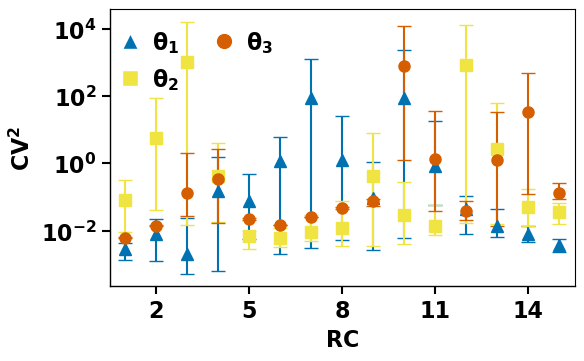

[k_nei, K, L] = [10, 3, 6]
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'lo

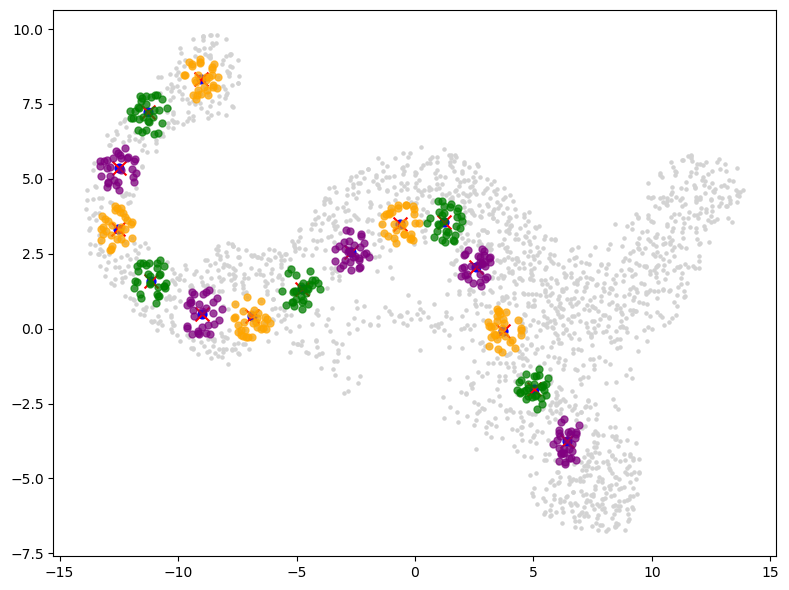

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

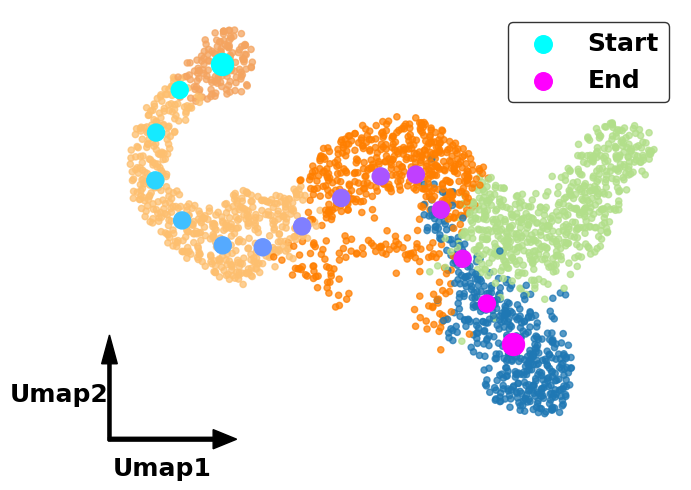

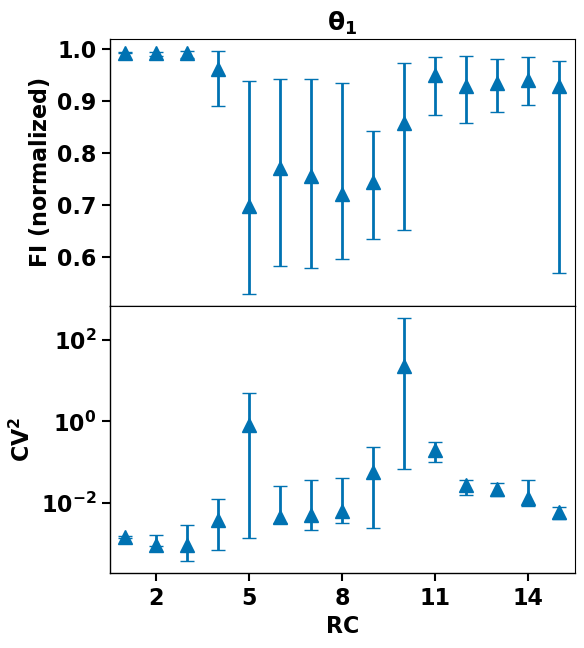

new_array.shape (15, 30, 3)
y: [1.4750516e-03 9.5518306e-04 9.0951403e-04 3.8987999e-03 8.3570492e-01
 4.5476165e-03 5.0002444e-03 6.3759484e-03 5.6886155e-02 2.3081562e+01
 1.9504286e-01 2.8006993e-02 2.2155600e-02 1.3602421e-02 5.9583937e-03]
max_vals: [1.51352957e-03 1.62168010e-03 2.83458759e-03 1.22779785e-02
 4.89213037e+00 2.55684536e-02 3.65536883e-02 4.11219262e-02
 2.36421272e-01 3.36699768e+02 3.08640569e-01 3.63526717e-02
 3.13581638e-02 3.73385809e-02 8.01361259e-03]
min_vals: [0.00139554 0.00087387 0.00037637 0.00072085 0.00138766 0.00315733
 0.00214701 0.00322757 0.00249882 0.06915065 0.10256997 0.01583086
 0.01514331 0.00855583 0.00406712]
error: [[7.95068918e-05 8.13175575e-05 5.33140032e-04 3.17794760e-03
  8.34317267e-01 1.39028672e-03 2.85322987e-03 3.14838043e-03
  5.43873347e-02 2.30124111e+01 9.24728885e-02 1.21761374e-02
  7.01228902e-03 5.04658930e-03 1.89127540e-03]
 [3.84779414e-05 6.66497042e-04 1.92507356e-03 8.37917812e-03
  4.05642557e+00 2.10208371e-02 3

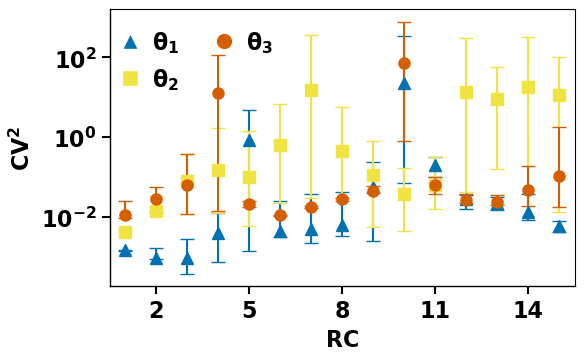

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighb

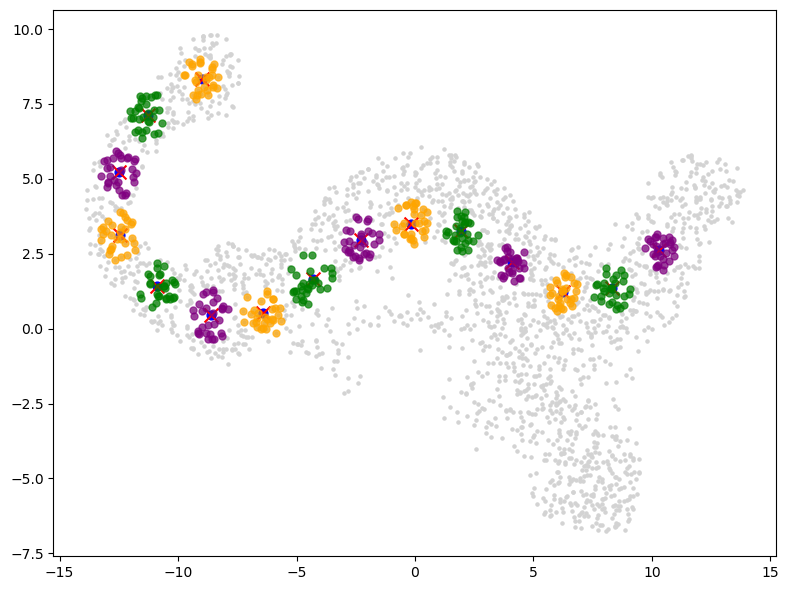

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

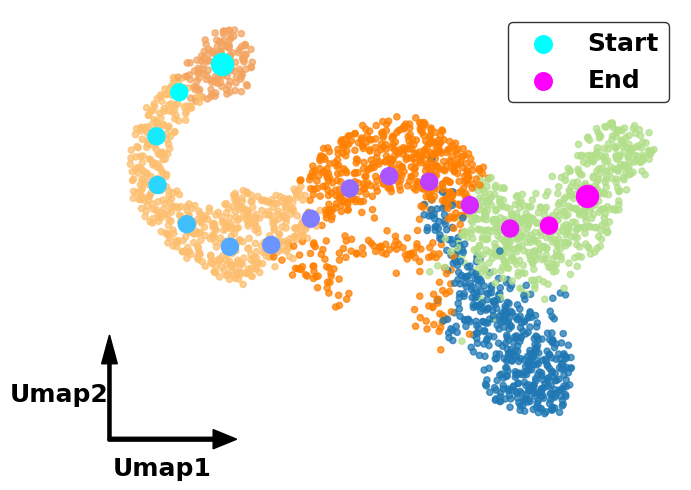

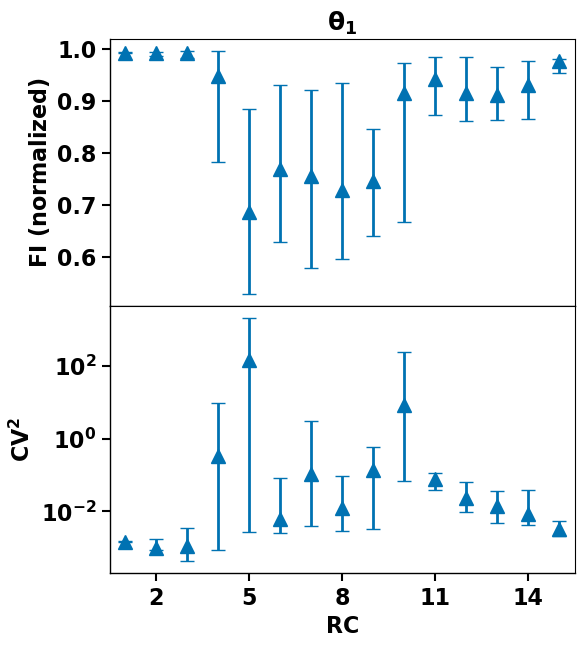

new_array.shape (15, 30, 3)
y: [1.4750517e-03 9.5291052e-04 1.1038001e-03 3.2442567e-01 1.4118234e+02
 6.1963298e-03 1.0932841e-01 1.2730563e-02 1.3494998e-01 8.3601265e+00
 7.6308034e-02 2.3731878e-02 1.3662530e-02 8.6512091e-03 3.3565073e-03]
max_vals: [1.5135296e-03 1.7060777e-03 3.5647189e-03 9.5693512e+00 2.0007834e+03
 8.3183929e-02 3.0251989e+00 9.1246635e-02 5.8236605e-01 2.3872560e+02
 1.1659525e-01 6.3361451e-02 3.7284691e-02 3.8367305e-02 5.5654692e-03]
min_vals: [0.00139554 0.00087395 0.00042845 0.000873   0.00266872 0.002516
 0.00389821 0.00281658 0.00318591 0.06938259 0.03954335 0.00928704
 0.00472323 0.004302   0.00206722]
error: [[7.9507008e-05 7.8957702e-05 6.7535182e-04 3.2355267e-01 1.4117967e+02
  3.6803293e-03 1.0543020e-01 9.9139875e-03 1.3176407e-01 8.2907438e+00
  3.6764681e-02 1.4444840e-02 8.9392997e-03 4.3492094e-03 1.2892827e-03]
 [3.8477825e-05 7.5316720e-04 2.4609189e-03 9.2449255e+00 1.8596011e+03
  7.6987602e-02 2.9158704e+00 7.8516074e-02 4.4741607e-01 

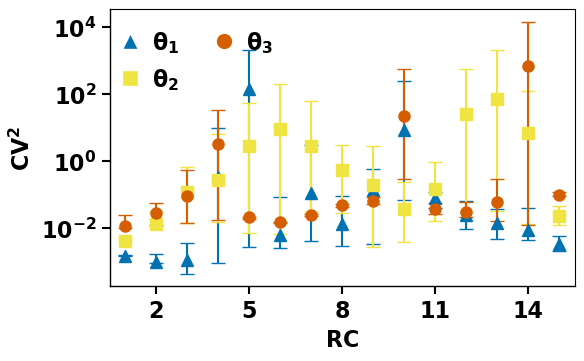

[k_nei, K, L] = [10, 3, 10]
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'l

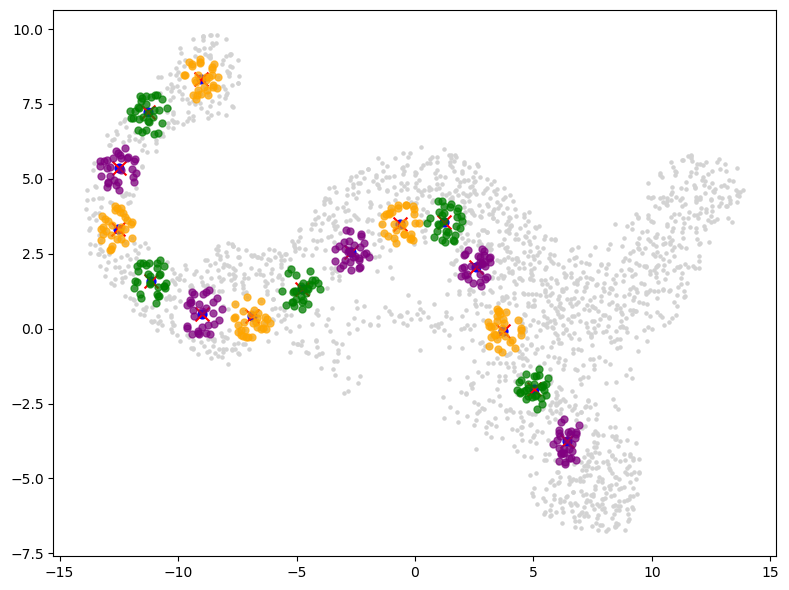

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

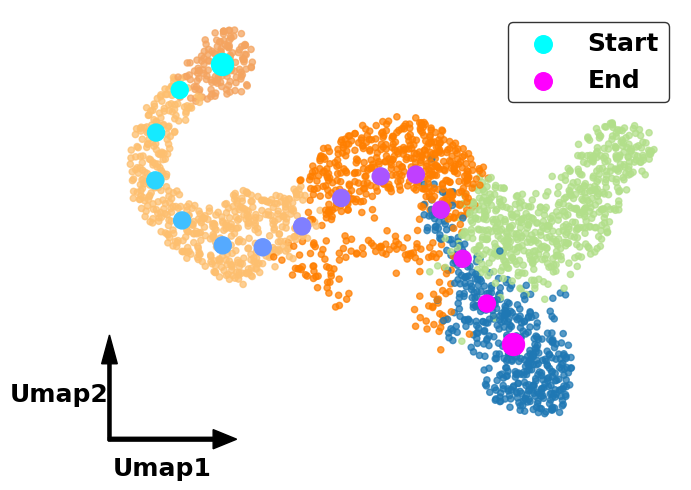

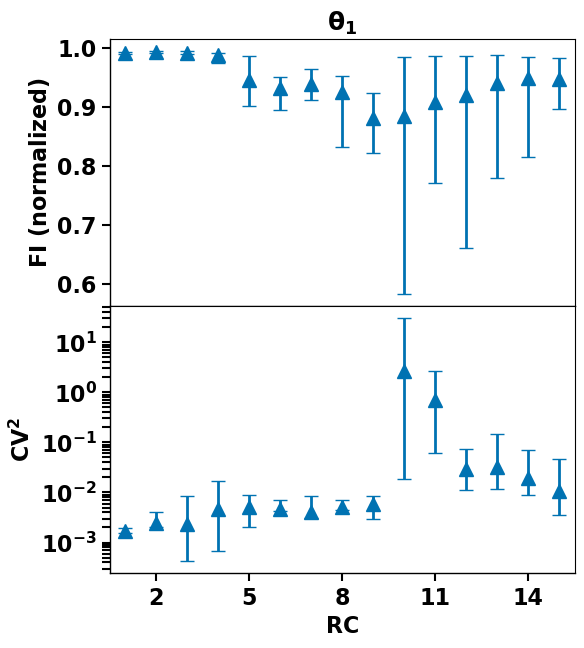

new_array.shape (15, 30, 3)
y: [1.7008759e-03 2.4162575e-03 2.3532573e-03 4.6384255e-03 5.0931680e-03
 4.6965773e-03 4.1440576e-03 5.0252704e-03 5.9427521e-03 2.7040780e+00
 6.8615490e-01 2.9079838e-02 3.1705637e-02 1.9688278e-02 1.0653601e-02]
max_vals: [1.9483964e-03 4.1460409e-03 8.4573738e-03 1.6593648e-02 8.7786829e-03
 6.9246837e-03 8.3253896e-03 7.0145885e-03 8.5297618e-03 2.9944483e+01
 2.6100047e+00 7.2931848e-02 1.4734076e-01 6.9956392e-02 4.5821615e-02]
min_vals: [0.00155041 0.00202069 0.00042485 0.00068446 0.00205824 0.00425213
 0.00305918 0.00438244 0.00291715 0.0186264  0.06048389 0.01111768
 0.01193547 0.00880857 0.00350033]
error: [[1.5046180e-04 3.9557088e-04 1.9284061e-03 3.9539677e-03 3.0349239e-03
  4.4445181e-04 1.0848748e-03 6.4283377e-04 3.0256035e-03 2.6854515e+00
  6.2567103e-01 1.7962161e-02 1.9770171e-02 1.0879712e-02 7.1532717e-03]
 [2.4752051e-04 1.7297834e-03 6.1041163e-03 1.1955222e-02 3.6855149e-03
  2.2281064e-03 4.1813320e-03 1.9893181e-03 2.5870097e-0

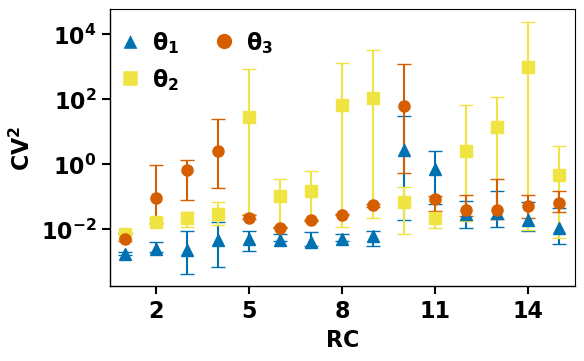

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighb

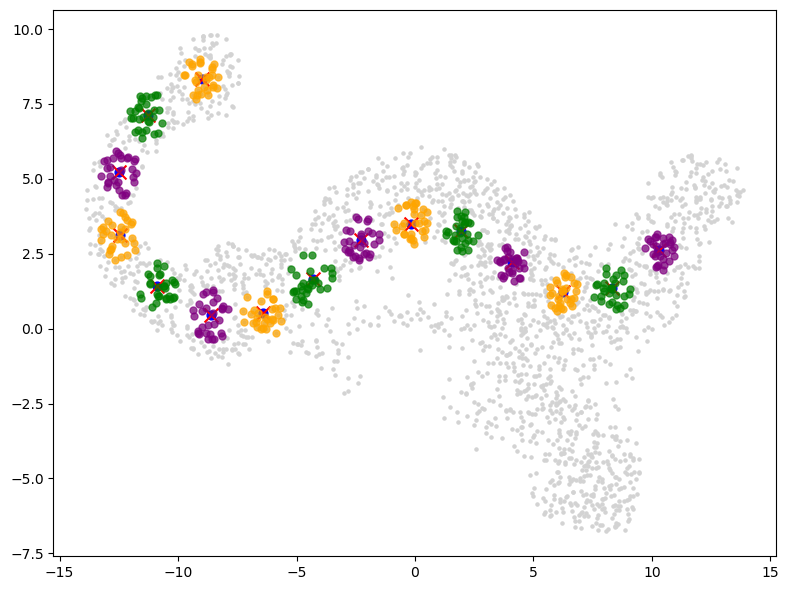

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

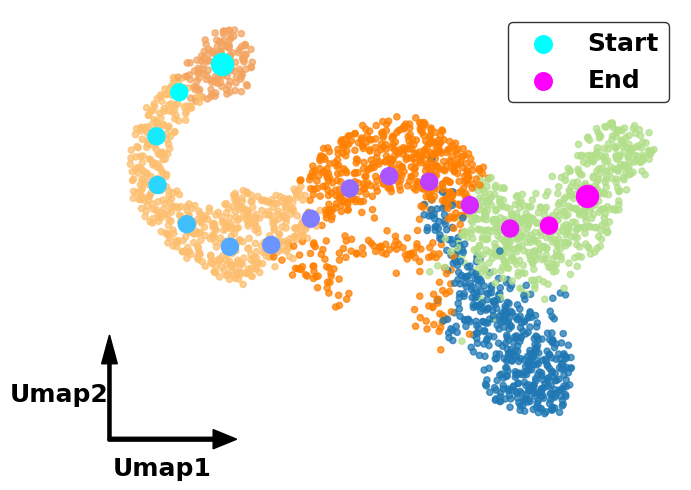

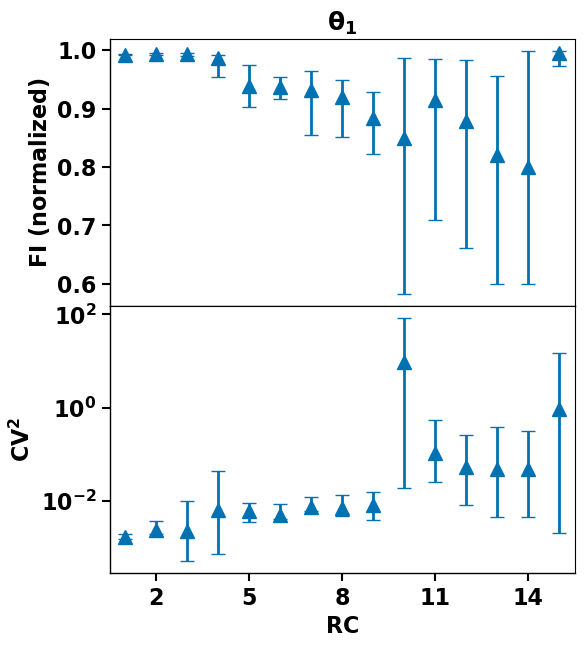

new_array.shape (15, 30, 3)
y: [1.70087605e-03 2.37100502e-03 2.29496998e-03 6.49705017e-03
 6.12452393e-03 5.07716369e-03 7.50312628e-03 7.10805319e-03
 7.97996577e-03 9.62382221e+00 1.06256984e-01 5.20697422e-02
 4.73247506e-02 4.84529100e-02 9.40950394e-01]
max_vals: [1.9483964e-03 3.7848128e-03 9.7515117e-03 4.2910498e-02 8.9257220e-03
 8.4714582e-03 1.1920891e-02 1.3147279e-02 1.5426947e-02 8.1744980e+01
 5.4391748e-01 2.5640053e-01 3.8250855e-01 3.2179993e-01 1.5101547e+01]
min_vals: [0.00155041 0.00197895 0.00050994 0.00072376 0.00358459 0.00413377
 0.00604563 0.00463844 0.00390836 0.0186417  0.02524503 0.0079579
 0.00444052 0.00441346 0.00205552]
error: [[1.5046226e-04 3.9205397e-04 1.7850320e-03 5.7732887e-03 2.5399318e-03
  9.4339252e-04 1.4574947e-03 2.4696114e-03 4.0716059e-03 9.6051807e+00
  8.1011951e-02 4.4111837e-02 4.2884231e-02 4.4039454e-02 9.3889487e-01]
 [2.4752039e-04 1.4138077e-03 7.4565420e-03 3.6413446e-02 2.8011980e-03
  3.3942945e-03 4.4177645e-03 6.0392255e-

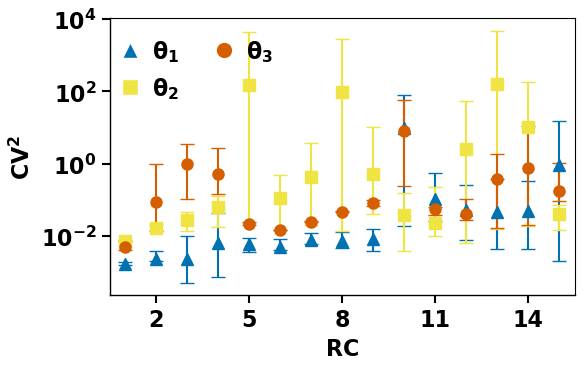

[k_nei, K, L] = [10, 3, 15]
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'l

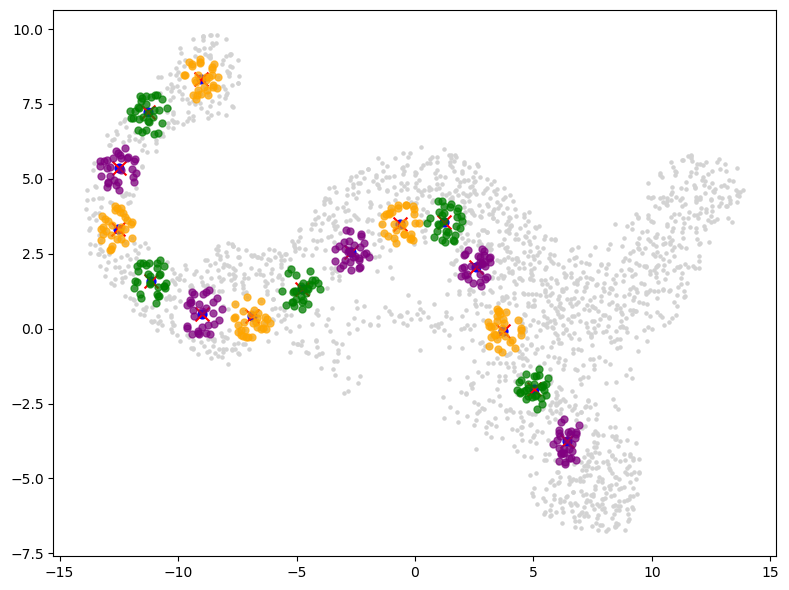

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

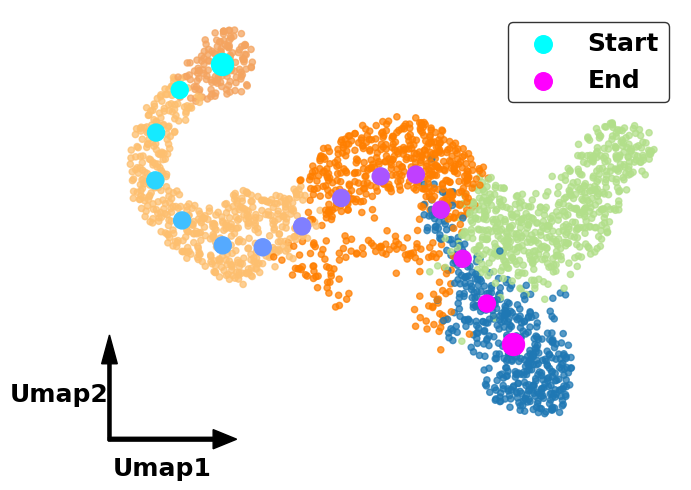

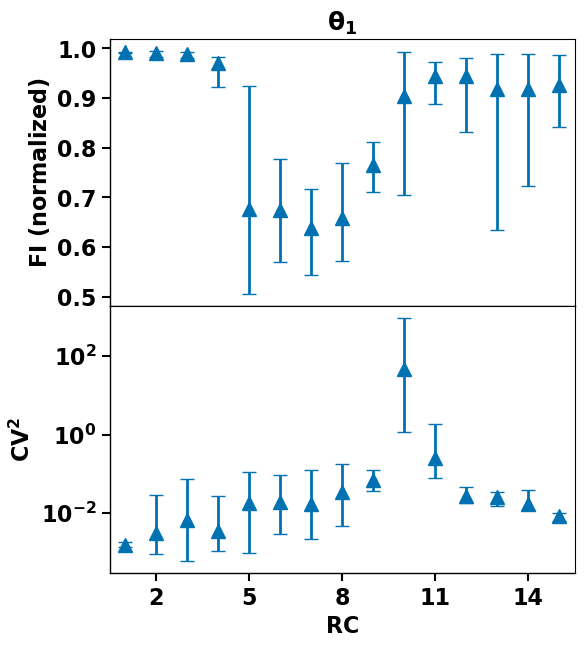

new_array.shape (15, 30, 3)
y: [1.5767030e-03 3.0417473e-03 6.6272980e-03 3.4865206e-03 1.8465947e-02
 1.9580137e-02 1.6963689e-02 3.4068111e-02 7.0210740e-02 4.8087769e+01
 2.5937933e-01 2.6820989e-02 2.5069952e-02 1.7445682e-02 8.4703602e-03]
max_vals: [1.7887414e-03 2.8980520e-02 7.1894959e-02 2.6958575e-02 1.1291549e-01
 9.3933597e-02 1.2814245e-01 1.7813905e-01 1.2222419e-01 9.1926898e+02
 1.8695148e+00 4.6345610e-02 3.5289854e-02 3.9221462e-02 1.0270421e-02]
min_vals: [1.3999037e-03 8.8046899e-04 5.9466856e-04 1.0828209e-03 9.6092734e-04
 2.9875310e-03 2.1222630e-03 4.5605227e-03 3.6367457e-02 1.1560358e+00
 7.6245785e-02 1.7565910e-02 1.5442806e-02 1.1632047e-02 6.2367716e-03]
error: [[1.76799367e-04 2.16127839e-03 6.03262940e-03 2.40369979e-03
  1.75050199e-02 1.65926069e-02 1.48414262e-02 2.95075886e-02
  3.38432826e-02 4.69317322e+01 1.83133543e-01 9.25507955e-03
  9.62714572e-03 5.81363495e-03 2.23358860e-03]
 [2.12038402e-04 2.59387717e-02 6.52676597e-02 2.34720558e-02
  9.

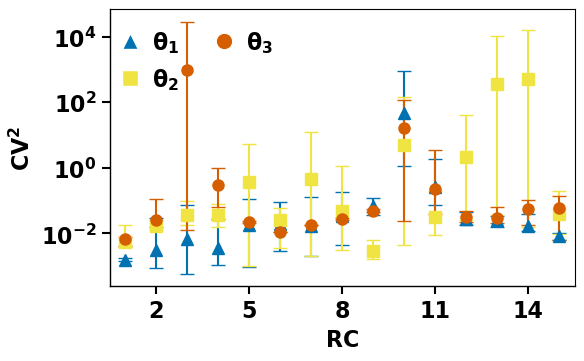

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighb

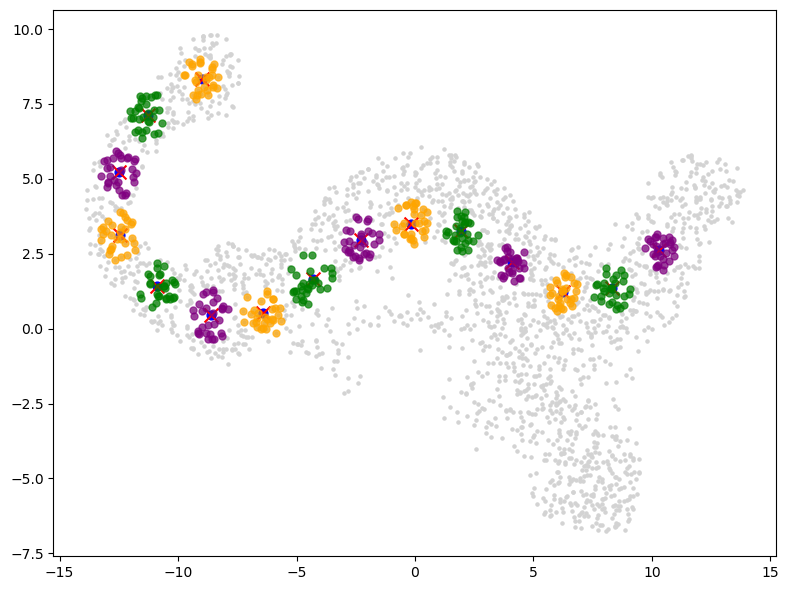

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

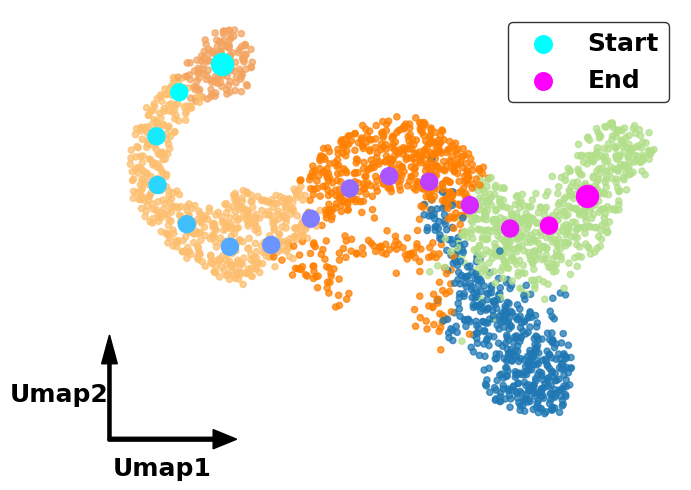

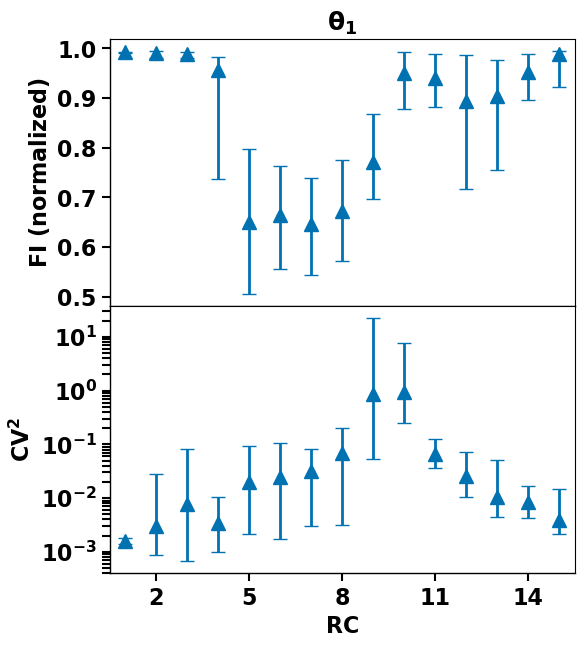

new_array.shape (15, 30, 3)
y: [0.0015767  0.00307554 0.0076891  0.00339121 0.02025821 0.02433013
 0.03228703 0.07005393 0.8657666  0.9333349  0.06502628 0.02598852
 0.01045923 0.00831912 0.00392629]
max_vals: [1.78874144e-03 2.76330505e-02 8.11721161e-02 1.06861414e-02
 9.32863802e-02 1.06000222e-01 8.10920224e-02 1.97537944e-01
 2.20474987e+01 7.80749846e+00 1.23883665e-01 7.10542873e-02
 5.14435284e-02 1.66401435e-02 1.50490226e-02]
min_vals: [0.0013999  0.00088206 0.00067147 0.00097613 0.00217729 0.00174543
 0.00296295 0.00315526 0.05243238 0.24552834 0.03653556 0.01030477
 0.0044385  0.00428256 0.00213395]
error: [[1.7679937e-04 2.1934740e-03 7.0176278e-03 2.4150792e-03 1.8080927e-02
  2.2584699e-02 2.9324081e-02 6.6898666e-02 8.1333423e-01 6.8780655e-01
  2.8490718e-02 1.5683750e-02 6.0207290e-03 4.0365690e-03 1.7923352e-03]
 [2.1203840e-04 2.4557516e-02 7.3483020e-02 7.2949356e-03 7.3028162e-02
  8.1670091e-02 4.8804995e-02 1.2748402e-01 2.1181732e+01 6.8741636e+00
  5.8857389e-

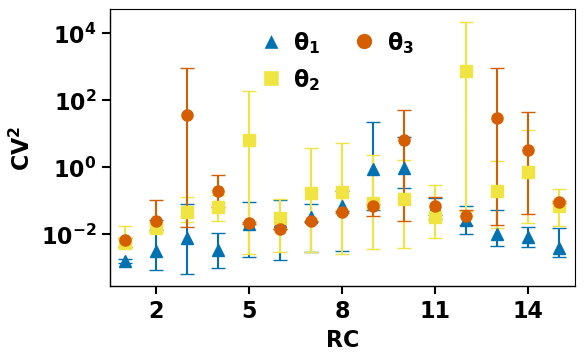

In [4]:
k_nei_list = [10]
K_list = [3]
L_list = [3, 6, 10, 15]
# L_list = [6]

param_combinations = list(itertools.product(k_nei_list, K_list, L_list))

for k_nei, K, L in param_combinations:
    [k_nei, K, L] = [k_nei, K, L]
    print(f"[k_nei, K, L] = [{k_nei}, {K}, {L}]")
    data_name = "EG_ab_bin"

    figure_path= f"/home/linux/桌面/Is single cell sloppy?/14_画图/figure/cv_2/{data_name}/" + str([k_nei,K,L]) + "/"
    [pca_dim, k_rc, d_pca, nrc] = [50, 30, 10, 10]
    clusters_name = "clusters"
    root_cluster = "Ngn3 low EP"
    loc_path_graph = 'upper right'
    basis = "umap"

    branch = [np.array(['Ngn3 low EP', 'Ngn3 high EP', 'Fev+', 'Alpha']), 
            np.array(['Ngn3 low EP', 'Ngn3 high EP', 'Fev+', 'Beta']) ]

    for t_list in (branch):

        branch_name = t_list[-1]
        adata0 = scv.read(data_path+data_name+'.h5ad', cache=True)
        adata = adata0.copy()
        scv.pp.pca(adata, n_comps=pca_dim)
        scv.pp.neighbors(adata, n_neighbors=k_nei)
        scv.pp.moments(adata, n_pcs=pca_dim, n_neighbors=k_nei)
        scv.tl.velocity(adata)
        print(adata)

        # average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}_dpca_{d_pca}.npy') 
        # cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, rc_distance= "X_pca", n_nei=k_rc, dim_n=10)            
        # average_path = np.array(adata[nearest_cell].obsm["X_umap"])
        for nrc in [15]:
            average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}.npy') 
            print("average_path.shape", average_path.shape)
            cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, n_nei = k_rc, rc_distance= "X_umap")
            # cell_arr是每个RC point处选出的细胞的索引。

            # fig = sc.pl.embedding(
            #     adata,
            #     # color=[clusters_name, "paga"],
            #     color=[clusters_name],
            #     basis="pca",
            #     color_map=cmap,
            #     return_fig=True
            # )

            X_pca = adata.obsm['X_pca']
            row = np.array([np.ones((k_nei,))*i for i in range(adata.shape[0])]).flatten()
            col = adata.uns['neighbors']['indices'].flatten()
            w_val = np.array([np.linalg.norm(X_pca[int(i),:]-X_pca[int(j),:]) for i,j in zip(row,col)])
            adj_val = np.ones(col.shape)
            A_mat = csr_matrix((adj_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
            A = A_mat
            W_mat = csr_matrix((w_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
            dc=np.mean(w_val)
            cell_nei=adata.uns['neighbors']['indices']
            nei_w=[]
            rho_arr=[]
            for ni in adata.uns['neighbors']['indices']:
                dij=np.array([np.linalg.norm(X_pca[int(ni[0]),:]-X_pca[int(i),:]) for i in ni[1:]])
                rho=np.sum(np.exp(-dij**2/dc**2))
                nei_w.append(np.exp(-dij**2/dc**2)/np.sum(np.exp(-dij**2/dc**2)))
                rho_arr.append(rho)
                
            rho_arr=np.array(rho_arr)/np.amax(rho_arr)
            nei_w=np.array(nei_w)
            nei_w=np.hstack((np.ones((nei_w.shape[0],1)),nei_w))/2

            def smooth_func(X_val,cell_nei=cell_nei,nei_w=nei_w):
                X_s=X_val.copy()
                for ci in range(len(X_val)):
                    X_s[ci]=np.dot(X_val[cell_nei[ci,:]],nei_w[ci,:])
                return X_s

            if basis == "umap":
                X_umap = adata.obsm['X_umap']
                X_plt = X_umap[:,0]
                Y_plt = X_umap[:,1]
                X_min = np.min(X_plt)
                X_max = np.max(X_plt)
                Y_min = np.min(Y_plt)
                Y_max = np.max(Y_plt)
                X_len = (X_max-X_min)/5
                Y_len = (Y_max-Y_min)/5
                wid = min(X_len,Y_len)/30
                X_ori = X_min-wid*10
                Y_ori = Y_min-wid*10
            elif basis == "pca":
                X_umap = adata.obsm['X_pca'][:, :2]
                X_plt = X_umap[:,0]
                Y_plt = X_umap[:,1]
                X_min = np.min(X_plt)
                X_max = np.max(X_plt)
                Y_min = np.min(Y_plt)
                Y_max = np.max(Y_plt)
                X_len = (X_max-X_min)/5
                Y_len = (Y_max-Y_min)/5
                wid = min(X_len,Y_len)/30
                X_ori = X_min-wid*10
                Y_ori = Y_min-wid*10

            X = torch.tensor(adata.layers['Ms'], dtype=torch.float32) 
            Encoder_path = "/home/linux/桌面/Is single cell sloppy?/11_PAGA_spectrum/encoder/"
            # for pca in [X_pca, eigengene, hotspot]:

            model_path = Encoder_path + data_name+' '+str([k_nei,K,L])+'/'
            eigengene = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_eigengene_X.npy")
            hotspot = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_hs_X.npy")
            model_name = f"{model_path}encoder.pt"
            model = torch.load(f'{model_name}')
            mu, sigma = model(torch.tensor(X))
            mu_learned = mu.detach().numpy()

            sigma_learned = sigma.detach().numpy()
            Fisher_g=np.zeros((X.shape[0],L*2,L*2))
            for i in range(X.shape[0]):
                for j in range(L):
                    Fisher_g[i,j,j]=1/sigma_learned[i,j]**2
                    Fisher_g[i,L+j,L+j]=2/sigma_learned[i,j]**2
            Fisher_g_diag = np.zeros([X.shape[0],L*2])
            for i in range(X.shape[0]):
                Fisher_g_diag[i] = np.diag(Fisher_g[i])
            ## 1_1这一步用了一个神经网络 pca -> Z(mu,sigma), 然后求出这个网络的pZ_pEg。
            for pca in [eigengene]:
                print("pca.shape:", pca.shape)
                reset_seeds(0) # 0
                model = nn.Sequential(
                    nn.Linear(pca.shape[1], 128),
                    nn.ReLU(),
                    nn.Linear(128,64),
                    nn.ReLU(),
                    nn.Linear(64,2*L),
                )
                loss_fn = nn.MSELoss()
                optimizer = Adam(model.parameters(), lr=0.01, weight_decay=0.001)#, momentum=0.2
                x_in=torch.tensor(pca, dtype=torch.float32)
                latent_z = np.hstack((mu_learned,sigma_learned))
                x_out=torch.tensor(latent_z.astype(np.float32))
                for epoch in range(500): # 200  # NOTE:参数knei K L 10 3 10 是200的时候，训练得到的model(x_in)每个细胞都是一样的值，跑到local minimal中去了应该。
                    # break
                    optimizer.zero_grad()
                    output = model(x_in)
                    loss = loss_fn(output,x_out) 

                    # # NOTE:这个神经网络训练的时候有时候会报Nan，所以加了这段。如果算到某个loss是Nan不要让损失传递下去。
                    # if not torch.isfinite(loss):
                    #     print("❌ loss 出问题了，epoch =", epoch)
                    #     break

                    loss.backward()
                    optimizer.step()

                output = model(x_in)

                print("model output NaN:", torch.isnan(output).sum().item())
                print("model output Inf:", torch.isinf(output).sum().item())
                pZ_ppca = p_out_p_in(pca, model, dim_out=2 * L)
                print("pZ_ppca NaN:", np.isnan(pZ_ppca).sum())
                print("pZ_ppca Inf:", np.isinf(pZ_ppca).sum())


                ### 链式法则（已知FI_Z），求出FI_pca。
                FI_pca = np.einsum("ijk,ij,ijh->ikh",pZ_ppca, Fisher_g_diag, pZ_ppca)
                print("FI_pca.shape:", FI_pca.shape)
                # FI_Eg_diag = FI_Eg[:, range(eigengene.shape[1]), range(eigengene.shape[1])]
                # U_FI_Eg[i]的列向量是特征向量。Ax = /lamba x (从这可以看出x是列向量)
                # 不过U_FI_Eg[i]的行向量和列向量的模长都是1.而且行和行彼此正交。列和列彼此正交。这是因为UU_T = I. U是正交矩阵。
                U_FI_Eg, S_FI_Eg, Vt_FI_Eg = np.linalg.svd(FI_pca, full_matrices=False)
                print("svd后(U_FI_Eg, S_FI_Eg, Vt_FI_Eg)：",U_FI_Eg.shape, S_FI_Eg.shape, Vt_FI_Eg.shape)

                # rc_path(adata, mu_learned, sigma_learned, average_path, basis, k_nei, data_name)
                cell_arr_plot(average_path, cell_arr, X_umap)
                rc_path_celltype(adata, average_path, basis, data_name, save = save, figure_path = figure_path, branch_name  = branch_name)
                    
                dim = 3 # 这个参数dim是指前多少个参数参与画图。
                # U_FI_Eg和pca的各列都是正交的才可以这么算。cell_i_的pca坐标（向量）点积u1得到的就是u1的坐标，这其实就是在u1上做投影。
                # NOTE:这可能是为什么eigengene和hotspot不行的原因，eigengene的各坐标系间不是正交的。
                pca_svd_rc_variance_all, pca_svd_rc_mean_all= compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L, simple=dim/2, cv= True)
                pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])
                # plot_all_variances_odd(pca_svd_rc_variance_all, share_y = False)
                FI_VAR_double_grid(S_FI_Eg, pca_svd_rc_variance_all, pca, 0.5, cell_arr, norm=True, simple= True, 
                                save = save, figure_path = figure_path, branch_name  = branch_name)

                exclude_indices = []
                all_indices = list(range(len(pca_svd_rc_variance_all)))

                # keep_indices 是各个RC point的索引。这里是为了舍去不想要的RC point
                keep_indices = [i for i in all_indices if i not in exclude_indices]
                new_array = np.array(pca_svd_rc_variance_all)[keep_indices]
 
                print("new_array.shape", new_array.shape)

                variance_along_rc(cell_arr, new_array, dim = dim, save = save, figure_path = figure_path, branch_name  = branch_name)

                # print("pca_svd_rc_mean_all:")
                # print(np.array(pca_svd_rc_mean_all))